
# **Predicción de cancelaciones de reservas hoteleras mediante Machine Learning**

El dataset Hotel Booking Demand (Kaggle) contiene 119.390 reservas reales de dos hoteles en Portugal, uno resort y uno urbano, entre 2015 y 2017. Cada registro describe una reserva mediante 32 variables categóricas y numéricas, como la anticipación de la reserva, la duración de la estancia, el número de huéspedes, el tipo de habitación, el canal de venta, el país de origen y la tarifa diaria.

El objetivo es predecir si una reserva será cancelada (variable is_canceled), un problema de clasificación binaria. Anticipar las cancelaciones ayuda a los hoteles a estimar mejor su ocupación real, reducir pérdidas y definir mejores políticas de precios y depósitos.

# **Proceso ETL**

El tratamiento de los datos sigue un flujo **ETL**:

- **E (Extracción):** obtener los datos desde su fuente (Kaggle) y cargarlos en un DataFrame.
- **T (Transformación):** inspeccionar, renombrar, limpiar y preparar las variables para el modelo.
- **L (Carga):** dejar el dataset limpio y listo para el modelado.

Cada etapa guarda su resultado en una variable nueva (por ejemplo **datos_originales**, **datos_renombrados**, **datos_sin_duplicados**), sin modificar la anterior. Así cualquier celda se puede ejecutar varias veces sin dañar los datos, y cada etapa se puede revisar en cualquier momento.

# **E: Extracción**

## **Paso 1. Importación de librerías**

In [ ]:
import math
import os
import platform

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Descarga de archivos al computador, disponible solo en Colab
try:
    from google.colab import files as archivos_colab
except ImportError:
    archivos_colab = None

# Configuración general de los gráficos
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e0e0e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 11,
})

## **Paso 2. Constantes del proyecto**

Todas las constantes del proyecto se definen en este bloque: nombres de columnas, grupos de variables, umbrales del análisis y de la limpieza, parámetros de los modelos, experimentos, rutas y colores. Así cualquier ajuste se hace en un solo lugar.

In [ ]:
# Datos
NOMBRE_DATASET_KAGGLE = "jessemostipak/hotel-booking-demand"
NOMBRE_ARCHIVO_DATOS = "hotel_bookings.csv"

# Traducción de cada nombre original (inglés) a su nombre en español,
# para tener un contexto más natural
NOMBRES_EN_ESPANOL = {
    "hotel": "tipo_hotel",
    "is_canceled": "target_cancelada",
    "lead_time": "dias_anticipacion",
    "arrival_date_year": "anio_llegada",
    "arrival_date_month": "mes_llegada",
    "arrival_date_week_number": "semana_llegada",
    "arrival_date_day_of_month": "dia_llegada",
    "stays_in_weekend_nights": "noches_fin_semana",
    "stays_in_week_nights": "noches_entre_semana",
    "adults": "adultos",
    "children": "ninos",
    "babies": "bebes",
    "meal": "regimen_comidas",
    "country": "pais_origen",
    "market_segment": "segmento_mercado",
    "distribution_channel": "canal_distribucion",
    "is_repeated_guest": "cliente_recurrente",
    "previous_cancellations": "cancelaciones_previas",
    "previous_bookings_not_canceled": "reservas_previas_no_canceladas",
    "reserved_room_type": "habitacion_reservada",
    "assigned_room_type": "habitacion_asignada",
    "booking_changes": "cambios_reserva",
    "deposit_type": "tipo_deposito",
    "agent": "agente",
    "company": "empresa",
    "days_in_waiting_list": "dias_lista_espera",
    "customer_type": "tipo_cliente",
    "adr": "tarifa_diaria_promedio",
    "required_car_parking_spaces": "parqueaderos_solicitados",
    "total_of_special_requests": "solicitudes_especiales",
    "reservation_status": "estado_reserva",
    "reservation_status_date": "fecha_estado_reserva",
}

VARIABLE_OBJETIVO = "target_cancelada"

# Grupos de variables
VARIABLES_NUMERICAS = [
    "dias_anticipacion", "anio_llegada", "semana_llegada", "dia_llegada",
    "noches_fin_semana", "noches_entre_semana", "adultos", "ninos", "bebes",
    "cliente_recurrente", "cancelaciones_previas", "reservas_previas_no_canceladas",
    "cambios_reserva", "dias_lista_espera", "tarifa_diaria_promedio",
    "parqueaderos_solicitados", "solicitudes_especiales",
]
VARIABLES_NOMINALES = [
    "tipo_hotel", "pais_origen", "segmento_mercado", "canal_distribucion",
    "habitacion_reservada", "habitacion_asignada", "tipo_deposito",
    "agente", "empresa", "tipo_cliente",
]
VARIABLES_ORDINALES = ["mes_llegada", "regimen_comidas"]

# Orden natural de las categorías de cada variable ordinal
ORDEN_ORDINALES = {
    "mes_llegada": ["January", "February", "March", "April", "May", "June", "July",
                    "August", "September", "October", "November", "December"],
    "regimen_comidas": ["Undefined", "SC", "BB", "HB", "FB"],
}

# Variables continuas con cola larga, candidatas a transformarse
VARIABLES_A_TRANSFORMAR = ["dias_anticipacion", "noches_fin_semana", "noches_entre_semana", "tarifa_diaria_promedio"]

# Análisis exploratorio
MAXIMO_CATEGORIAS_GRAFICO = 10
ASIMETRIA_COLA_LARGA = 1

METODOS_CORRELACION = ["pearson", "spearman", "kendall"]
UMBRAL_SIN_CORRELACION = 0.05
UMBRAL_CORRELACION_DEBIL = 0.10
UMBRAL_DIFERENCIA = 0.10

UMBRAL_SIN_ASOCIACION = 0.10
UMBRAL_INFORMACION_SOSPECHOSA = 0.50
UMBRAL_CATEGORIAS = 20
LIMITES_V_CRAMER = [-np.inf, 0.10, 0.30, 0.50, np.inf]
NIVELES_ASOCIACION = ["despreciable", "débil", "moderada", "fuerte"]
LIMITES_VALOR_INFORMACION = [-np.inf, 0.02, 0.10, 0.30, 0.50, np.inf]
NIVELES_PODER_PREDICTIVO = ["no predictiva", "débil", "media", "fuerte", "sospechoso"]

# Limpieza y transformación
# Columnas que se eliminan y el motivo de cada una
COLUMNAS_A_ELIMINAR = {
    "estado_reserva": "revela si la reserva se canceló",
    "fecha_estado_reserva": "revela cuándo se canceló o se cumplió la reserva",
    "habitacion_asignada": "se asigna al llegar, algo que no ocurre si se cancela",
    "anio_llegada": "no sirve para predecir años futuros",
}
TARIFA_MAXIMA_VALIDA = 1000

# Categoría más frecuente de cada variable, según el Paso 13
CATEGORIA_MAS_FRECUENTE = {
    "canal_distribucion": "TA/TO",
    "segmento_mercado": "Online TA",
}

# Variable original y nombre del indicador que la reemplaza
INDICADORES_BINARIOS = {
    "cancelaciones_previas": "tuvo_cancelaciones_previas",
    "reservas_previas_no_canceladas": "tuvo_reservas_previas",
    "dias_lista_espera": "estuvo_en_lista_espera",
    "parqueaderos_solicitados": "solicito_parqueadero",
}

VARIABLES_CON_LOGARITMO = ["noches_entre_semana", "noches_fin_semana"]
MAXIMO_ADULTOS = 4

# Número de cada mes, de 1 (enero) a 12 (diciembre)
CODIGOS_MES = {}
numero_mes = 1
for mes in ORDEN_ORDINALES["mes_llegada"]:
    CODIGOS_MES[mes] = numero_mes
    numero_mes = numero_mes + 1

CODIGOS_REGIMEN = {"SC": 0, "BB": 1, "HB": 2, "FB": 3}

# Rango esperado de la tasa de cancelación del dataset limpio
TASA_CANCELACION_MINIMA = 0.20
TASA_CANCELACION_MAXIMA = 0.40

RUTA_DATOS_LIMPIOS = "reservas_limpias.csv"

# Modelado
PROPORCION_PRUEBA = 0.20
SEMILLA = 42

PREDICTORAS_CATEGORICAS = [
    "tipo_hotel", "pais_origen", "segmento_mercado", "canal_distribucion",
    "habitacion_reservada", "tipo_deposito", "agente", "tipo_cliente",
]
FRECUENCIA_MINIMA_CATEGORIA = 0.01

MAXIMO_ITERACIONES_LOGISTICA = 1000
ARBOLES_RANDOM_FOREST = 300
MINIMO_RESERVAS_POR_HOJA = 5

REPETICIONES_PERMUTACION = 5
APORTE_MINIMO = 0.001
UMBRAL_SOBREAJUSTE = 0.05

# Experimentos
COLUMNAS_EXCLUIDAS_EXPERIMENTO_1 = ["semana_llegada"]
COLUMNAS_EXCLUIDAS_EXPERIMENTO_2 = ["mes_llegada"]

# Exportación
CARPETA_MODELOS = "modelos"
RUTA_MODELO = os.path.join(CARPETA_MODELOS, "modelo_cancelaciones.joblib")
UMBRAL_DECISION = 0.5
LIBRERIAS_APLICACION = {"scikit-learn": sklearn, "pandas": pd, "numpy": np, "joblib": joblib}

# Gráficos
COLOR_BARRAS = "#2a78d6"
COLOR_BAJO_APORTE = "#bdbdbd"
COLORES_MODELOS = ["#2a78d6", "#eb6834", "#1baf7a"]

## **Paso 3. Descarga y lectura del dataset**

In [ ]:
def descargar_datos() -> str:
    """Descarga la última versión del dataset desde Kaggle y devuelve la carpeta donde quedó guardado."""
    carpeta = kagglehub.dataset_download(NOMBRE_DATASET_KAGGLE)
    print("Carpeta del dataset:", carpeta)
    return carpeta


def leer_datos(carpeta: str) -> pd.DataFrame:
    """Lee el archivo de reservas de la carpeta indicada y lo devuelve como tabla de pandas."""
    ruta_archivo = os.path.join(carpeta, NOMBRE_ARCHIVO_DATOS)
    return pd.read_csv(ruta_archivo)


datos_originales = leer_datos(descargar_datos())
print("Dimensiones del dataset:", datos_originales.shape)
datos_originales.head()

# **Variables predictoras del dataset Hotel Booking Demand**

## Variables numéricas

1. **lead_time** (tiempo de anticipación): días transcurridos entre la fecha de la reserva y la fecha de llegada.

3. **arrival_date_week_number** (semana de llegada): número de la semana del año de la llegada (1 a 53).
4. **arrival_date_day_of_month** (día de llegada): día del mes de la llegada (1 a 31).
5. **stays_in_weekend_nights** (noches de fin de semana): noches de sábado o domingo que el huésped se queda o reservó.
6. **stays_in_week_nights** (noches entre semana): noches de lunes a viernes que el huésped se queda o reservó.
7. **adults** (adultos): número de adultos en la reserva.
8. **children** (niños): número de niños en la reserva.
9. **babies** (bebés): número de bebés en la reserva.
10. **is_repeated_guest** (cliente recurrente): indica si el cliente ya se había hospedado antes (1 = sí, 0 = no).
11. **previous_cancellations** (cancelaciones previas): número de reservas que el cliente canceló anteriormente.
12. **previous_bookings_not_canceled** (reservas previas no canceladas): número de reservas anteriores del cliente que no se cancelaron.
13. **booking_changes** (cambios en la reserva): número de modificaciones hechas a la reserva antes del check-in o la cancelación.
14. **days_in_waiting_list** (días en lista de espera): días que la reserva estuvo en lista de espera antes de confirmarse.
15. **adr** (tarifa diaria promedio): precio promedio por noche, calculado como el costo total del alojamiento dividido entre el número de noches.
16. **required_car_parking_spaces** (parqueaderos solicitados): número de espacios de parqueo que pidió el cliente.
17. **total_of_special_requests** (solicitudes especiales): número de peticiones especiales del cliente, como cama doble o piso alto.

## Variables categóricas nominales

18. **hotel** (tipo de hotel): hotel resort o hotel urbano.
19. **country** (país de origen): país de procedencia del cliente.
20. **market_segment** (segmento de mercado): tipo de mercado de la reserva, como agencias en línea, grupos, corporativo o directo.
21. **distribution_channel** (canal de distribución): medio por el que se hizo la reserva, como agencias de viaje, directo o corporativo.
22. **reserved_room_type** (tipo de habitación reservada): código del tipo de habitación solicitada.
23. **assigned_room_type** (tipo de habitación asignada): código del tipo de habitación entregada; puede diferir de la reservada.
24. **deposit_type** (tipo de depósito): indica si se pidió depósito y de qué tipo (sin depósito, no reembolsable o reembolsable).
25. **agent** (agente): identificador de la agencia de viajes que hizo la reserva.
26. **company** (empresa): identificador de la empresa que hizo o pagó la reserva.
27. **customer_type** (tipo de cliente): transitorio, contrato, grupo o transitorio asociado a otra reserva.

## Variables categóricas ordinales

28. **arrival_date_month** (mes de llegada): mes de la llegada, de enero a diciembre; tiene un orden natural.
29. **meal** (régimen de comidas): plan de alimentación contratado, ordenable por nivel de servicio: **SC** (sin comidas), **BB** (solo desayuno), **HB** (media pensión) y **FB** (pensión completa).

## Variables excluidas del modelo

- **is_canceled** (reserva cancelada): variable objetivo; vale 1 si la reserva se canceló y 0 si no.
- **reservation_status** (estado de la reserva) y **reservation_status_date** (fecha del estado de la reserva): se excluyen porque revelan el resultado de la reserva y generan fuga de datos.

# **T: Transformación**

## Paso 4. Renombrado de variables al español

Hacemos la traducción de los nombres de las 32 columnas a español, sin tildes ni ñ (por ejemplo **anio_llegada**, **ninos**) para evitar problemas de codificación. La variable objetivo **is_canceled** pasa a llamarse **target_cancelada**.

In [ ]:
def renombrar_columnas(datos: pd.DataFrame) -> pd.DataFrame:
    """Traduce al español los nombres de las columnas; se detiene si alguna no tiene traducción."""
    for columna in datos.columns:
        if columna not in NOMBRES_EN_ESPANOL:
            raise ValueError(f"La columna {columna} no tiene traducción al español.")
    return datos.rename(columns=NOMBRES_EN_ESPANOL)


datos_renombrados = renombrar_columnas(datos_originales)
datos_renombrados.head()

## **Paso 5. Estructura del dataset: tipos de datos y valores no nulos**

**info()** muestra el tipo de cada columna y cuántos valores no nulos tiene. Dentro del ETL sirve para decidir qué transformar: columnas con faltantes que hay que imputar o eliminar, y columnas con un tipo incorrecto que hay que convertir (por ejemplo, fechas leídas como texto).

In [ ]:
datos_renombrados.info()

## Paso 6. Estadísticas descriptivas de las variables numéricas

**describe()** resume cada variable numérica (conteo, media, desviación, mínimo, cuartiles y máximo). Dentro del ETL permite detectar valores imposibles o atípicos que se deben corregir en la limpieza, como tarifas negativas, estancias de 0 noches o reservas sin huéspedes.

In [ ]:
datos_renombrados.describe().T

## **Paso 7. Estadísticas descriptivas de las variables categóricas**

Para las columnas de texto, **describe()** muestra el número de categorías distintas, la más frecuente y su frecuencia. Dentro del ETL ayuda a decidir la codificación: las variables con muchas categorías (como **pais_origen**) requieren agrupar las poco frecuentes antes de codificarlas.

In [ ]:
datos_renombrados.describe(include="object").T

### **Análisis de las Variables Categóricas (Paso 7)**

El analisis descriptivo de las variables de texto revela las siguientes características clave sobre las reservas:

1.  **tipo_hotel**: Registra un total de **119.390** observaciones con **2** categorías únicas, donde el valor más frecuente (**top**) es **City Hotel** con una frecuencia (**freq**) de **79.330** reservas lo que representa el **66,4%** del total frente al hotel de tipo resort.

2.  **mes_llegada**: Cuenta con **12** categorías correspondientes a los meses del año, siendo **August** el mes con mayor volumen de visitas con **13.877** registros.

3.  **regimen_comidas**: Presenta **5** categorías donde la opción **BB** (Bed and Breakfast) predomina masivamente con **92.310** registros, abarcando el **77,3%** de la demanda.

4.  **pais origen**: Tiene **118.902** valores válidos distribuidos en **177** países de procedencia, destacando Portugal (**PRT**) como el origen más común con **48.590** reservas (**40,9%** del total con registro).

5.  **segmento_mercado**: Se divide en **8** segmentos diferentes, siendo las agencias online (**Online TA**) la categoría principal con **56.477** reservas.

6.  **canal_distribucion**: Registra **5** canales de distribución donde **TA/TO** (Agentes de Viajes y Operadores Turísticos) concentra la inmensa mayoría con **97.870** reservas.

7.  **habitacion_reservada**: Dispone de **10** tipos de habitaciones, donde la categoría **A** es la más solicitada de manera abrumadora con **85.994** registros.

8.  **habitacion_asignada**: Cuenta con **12** tipos de habitaciones y la categoría **A** vuelve a ser la más frecuente con **74.053** asignaciones reales al momento de la llegada.

9.  **tipo_deposito**: Contiene **3** opciones de garantía donde **No Deposit** (sin depósito) cubre casi toda la totalidad con **104.641** transacciones.

10.  **tipo_cliente**: Clasificado en **4** tipos, donde los clientes transitorios (**Transient**) representan el volumen principal con **89.613** registros.

11.  **estado_reserva**: Muestra **3** estados finales donde la mayoría de los registros figuran con check-out exitoso (**Check-Out**) en **75.166** ocasiones.

12.  **fecha_estado_reserva**: Tiene una alta dispersión con **926** fechas distintas, siendo el **2015-10-21** el día con mayor acumulación de actualizaciones con **1.461** registros.

## **Paso 8. Análisis de valores nulos y filas duplicadas**

Tabulamos, para cada variable con faltantes, el numero y el porcentaje de valores nulos, y luego el número y el porcentaje de filas duplicadas en todo el dataset.

In [ ]:
def tabular_nulos(datos: pd.DataFrame) -> pd.DataFrame:
    """Cuenta los valores nulos de cada variable y su porcentaje; solo muestra las que tienen nulos."""
    tabla = pd.DataFrame({
        "nulos": datos.isna().sum(),
        "porcentaje_nulos": (datos.isna().mean() * 100).round(2),
    })
    tabla = tabla[tabla["nulos"] > 0]
    return tabla.sort_values("porcentaje_nulos", ascending=False)


def tabular_duplicados(datos: pd.DataFrame) -> pd.DataFrame:
    """Cuenta las filas duplicadas del dataset y su porcentaje."""
    filas_duplicadas = datos.duplicated().sum()
    return pd.DataFrame({
        "filas_totales": [len(datos)],
        "filas_duplicadas": [filas_duplicadas],
        "porcentaje_duplicados": [round(filas_duplicadas / len(datos) * 100, 2)],
    })


display(tabular_nulos(datos_renombrados))
display(tabular_duplicados(datos_renombrados))

**Anomalías detectadas**

- **empresa**: 94,31 % nulos. Está casi vacía; conviene convertirla en un indicador binario (tiene o no tiene empresa).
- **agente**: 13,69 % nulos. El nulo indica una reserva hecha sin agencia; se imputa como una categoría propia.
- **pais_origen**: 0,41 % nulos (488 filas). Se imputan como país desconocido.
- **ninos**: 4 nulos. Se imputan con 0.
- **Duplicados**: 31.994 filas (26,8 %). El dataset no trae un identificador de reserva, así que pueden ser reservas idénticas reales (por ejemplo, grupos). Si se mantienen, inflan ciertos patrones y pueden quedar copias de una misma fila en entrenamiento y en prueba, lo que sobreestima el desempeño del modelo.

## **Paso 9. Revisión de los grupos de variables**

Las predictoras se agrupan en numéricas, categóricas nominales y categóricas ordinales; los grupos y el orden natural de las ordinales se definen en el bloque de constantes del Paso 2. Estas listas se reutilizan en los gráficos y más adelante en el preprocesamiento. Las variables **estado_reserva** y **fecha_estado_reserva** no se incluyen porque generan fuga de datos.

In [ ]:
print("Numéricas:", len(VARIABLES_NUMERICAS))
print("Nominales:", len(VARIABLES_NOMINALES))
print("Ordinales:", len(VARIABLES_ORDINALES))

## **Paso 10. Distribución de las variables numéricas**

con el codigo dibujamos un histograma por variable. En el título de cada gráfico aparece su asimetría (skewness): un valor mayor que 1 en valor absoluto indica una cola larga.

In [ ]:
def graficar_histogramas(datos: pd.DataFrame, variables: list[str]) -> None:
    """Dibuja un histograma por variable, con su asimetría en el título, en una cuadrícula de 4 columnas."""
    cantidad_filas = math.ceil(len(variables) / 4)
    plt.figure(figsize=(18, 4 * cantidad_filas))
    posicion = 1
    for variable in variables:
        plt.subplot(cantidad_filas, 4, posicion)
        plt.hist(datos[variable].dropna(), bins=50, color=COLOR_BARRAS, edgecolor="white", linewidth=0.4)
        plt.title(f"{variable}\nasimetría = {datos[variable].skew():.2f}")
        plt.ylabel("frecuencia")
        posicion = posicion + 1
    plt.tight_layout()
    plt.show()


graficar_histogramas(datos_renombrados, VARIABLES_NUMERICAS)

**Anomalías detectadas**

- **Presencia de colas muy largas a la derecha**: Los títulos de los gráficos confirman una fuerte asimetría positiva (valores mayores que 1,00) en la gran mayoría de las variables numéricas, destacando especialmente **bebes** (asimetría = 24.65), **cancelaciones_previas** (asimetría = 24.46) y **reservas_previas_no_canceladas** (asimetría = 23.54). Esto indica la presencia de una cola muy larga hacia valores altos.
- **Distribución de variables temporales**: Las variables **anio_llegada**, **semana_llegada** y **dia_llegada** muestran valores de asimetría cercanos a cero, lo que confirma que sus distribuciones son prácticamente simétricas y no presentan este tipo de anomalía.

## **Paso 11. Tabla de asimetría y colas de las variables numéricas**

Resumimos, para cada variable, su asimetría, el porcentaje de ceros, la mediana, el percentil 99 y el máximo. La columna **cola_larga** marca las variables con asimetría mayor que 1 en valor absoluto.

In [ ]:
def tabular_asimetria(datos: pd.DataFrame, variables: list[str]) -> pd.DataFrame:
    """Resume la asimetría, el porcentaje de ceros y los valores extremos de cada variable numérica."""
    tabla = pd.DataFrame({
        "asimetria": datos[variables].skew(),
        "porcentaje_ceros": (datos[variables] == 0).mean() * 100,
        "mediana": datos[variables].median(),
        "percentil_99": datos[variables].quantile(0.99),
        "maximo": datos[variables].max(),
    })
    tabla = tabla.round(2)
    tabla = tabla.sort_values("asimetria", ascending=False)

    # Cola larga: asimetría mayor que 1 hacia cualquiera de los dos lados
    tabla["cola_larga"] = tabla["asimetria"].abs() > ASIMETRIA_COLA_LARGA
    return tabla


tabular_asimetria(datos_renombrados, VARIABLES_NUMERICAS)

**Anomalías detectadas**

- **Presencia de colas largas**: De acuerdo con la tabla generada, **14 de las 17** variables numéricas tienen una asimetría mayor a 1,00 en valor absoluto. Solo las tres variables temporales de fecha muestran una distribución simétrica.
- **Extrema concentración de ceros**: El análisis de la columna **porcentaje_ceros** confirma que las siguientes variables están concentradas casi en su totalidad en el valor cero:
  - **bebes** (**99,23%** de ceros)
  - **reservas_previas_no_canceladas** (**96,97%** de ceros)
  - **dias_lista_espera** (**96,90%** de ceros)
  - **cliente_recurrente** (**96,81%** de ceros)
  - **cancelaciones_previas** (**94,57%** de ceros)
  - **parqueaderos_solicitados** (**93,79%** de ceros)
  - **ninos** (**92,80%** de ceros)
- **Propuesta de tratamiento**: Dado que transformar con logaritmo variables con alta concentracion de ceros no corrige la asimetría(logaritmo de cero no existe), estas variables son candidatas para ser transformadas en indicadores binarios (0 o 1) y esto es asi dado que no es conveniente eliminarlas dado que su naturaleza entrega información. Las variables numéricas continuas con asimetría que se evaluarán para transformación en el paso siguiente son **dias_anticipacion**, **noches_fin_semana**, **noches_entre_semana** y **tarifa_diaria_promedio**. Vease la tabla .describe() para las variables numéricas en la tabla del paso 6.


## **Paso 12. Comparación de transformaciones para las variables con cola larga**

Para cada candidata se compara la distribución original con el logaritmo (calculado sobre 1 más el valor, para admitir ceros) y con la raíz cuadrada. Los valores negativos de la tarifa se recortan a 0 solo para poder graficar.

In [ ]:
def graficar_transformaciones(datos: pd.DataFrame, variables: list[str]) -> None:
    """Grafica cada variable original, con logaritmo y con raíz cuadrada, para quedarnos con la de menor asimetría."""
    for variable in variables:
        serie = datos[variable].clip(lower=0)   # evita valores negativos

        original = serie
        logaritmo = np.log1p(serie)             # log(x + 1), funciona con ceros
        raiz = np.sqrt(serie)

        plt.figure(figsize=(16, 4))

        plt.subplot(1, 3, 1)                    # 1 fila, 3 columnas, gráfico 1
        plt.hist(original, bins=50, color=COLOR_BARRAS)
        plt.title(f"{variable} original\nasimetría = {original.skew():.2f}")

        plt.subplot(1, 3, 2)                    # gráfico 2
        plt.hist(logaritmo, bins=50, color=COLOR_BARRAS)
        plt.title(f"{variable} logaritmo\nasimetría = {logaritmo.skew():.2f}")

        plt.subplot(1, 3, 3)                    # gráfico 3
        plt.hist(raiz, bins=50, color=COLOR_BARRAS)
        plt.title(f"{variable} raíz cuadrada\nasimetría = {raiz.skew():.2f}")

        plt.tight_layout()
        plt.show()


graficar_transformaciones(datos_renombrados, VARIABLES_A_TRANSFORMAR)

**Anomalías detectadas**

- **noches_entre_semana**: la asimetría baja de 2,86 a -0,12 con el logaritmo. El logaritmo es adecuado.
- **noches_fin_semana**: baja de 1,38 a 0,19 con el logaritmo y a 0,06 con la raíz cuadrada. Ambas sirven.
- **dias_anticipacion**: el logaritmo sobrecorrige (de 1,35 a -0,87) porque hay muchas reservas con pocos días de anticipación; la raíz cuadrada da un mejor resultado (0,29).
- **tarifa_diaria_promedio**: no conviene transformarla. Su asimetría alta (10,53) no se debe a una cola larga real, sino a valores inválidos: una tarifa negativa y un atípico de 5.400 cuando la tarifa típica ronda los 100. Las transformaciones no corrigen ese problema: el logaritmo comprime el atípico, pero aleja los ~1.959 ceros hacia la izquierda y crea una cola artificial (asimetría de -3,74).

  **Recomendación:** eliminar los valores inválidos en lugar de transformar la variable. Esto se hace en el Paso 21, donde se comprueba que, sin esos valores, la asimetría baja a 0,93 y la variable puede usarse en su escala original.

## **Paso 13. Distribución de las variables categóricas nominales**

Se dibuja el porcentaje de reservas por categoría. En las variables con más de 10 categorías se muestran las 10 más frecuentes y el resto se agrupa como **Otras**. Los nulos aparecen como **Sin dato**.

In [ ]:
def preparar_categoria(serie: pd.Series) -> pd.Series:
    """Convierte la variable a texto y pone Sin dato donde hay vacíos."""
    serie = serie.fillna("Sin dato")
    serie = serie.astype(str)
    serie = serie.str.removesuffix(".0")   # el código 9.0 pasa a ser 9
    return serie


def graficar_nominales(datos: pd.DataFrame, variables: list[str], maximo_categorias: int) -> None:
    """Dibuja el porcentaje de reservas de cada categoría; agrupa en Otras las que superan el máximo."""
    for variable in variables:
        categorias = preparar_categoria(datos[variable])

        # Porcentaje de reservas por categoría (de mayor a menor)
        porcentajes = categorias.value_counts(normalize=True) * 100

        # Si hay muchas categorías, se dejan las principales y el resto va a "Otras"
        if len(porcentajes) > maximo_categorias:
            resto = porcentajes.iloc[maximo_categorias:].sum()
            porcentajes = porcentajes.iloc[:maximo_categorias].copy()
            porcentajes["Otras"] = resto

        # Orden de menor a mayor para que la barra más grande quede arriba
        porcentajes = porcentajes.sort_values()

        plt.figure(figsize=(10, 5))
        barras = plt.barh(porcentajes.index, porcentajes.values, color=COLOR_BARRAS)
        plt.bar_label(barras, fmt="%.1f%%", fontsize=8, padding=2)
        plt.title(f"{variable} ({datos[variable].nunique()} categorías)")
        plt.xlabel("porcentaje de reservas (%)")
        plt.tight_layout()
        plt.show()


graficar_nominales(datos_renombrados, VARIABLES_NOMINALES, MAXIMO_CATEGORIAS_GRAFICO)

**Anomalías detectadas**

- **Alta cardinalidad**: **pais_origen** (177 países, 164 con menos del 1 %), **agente** (333 valores) y **empresa** (352 valores). Codificarlas con one-hot generaría cientos de columnas; hay que agrupar las categorías poco frecuentes o usar otra codificación.
- **Desbalance fuerte entre categorías**: **pais_origen** concentra el 40,7 % en Portugal, **canal_distribucion** el 82 % en TA/TO y **tipo_deposito** el 87,7 % en No Deposit.
- **Categorías casi vacías o indefinidas**: **canal_distribucion** tiene 5 filas **Undefined**, **segmento_mercado** tiene 2, y **habitacion_reservada** tiene tipos con muy pocas filas (P con 12 y L con 6).
- **tipo_deposito**: el 99,4 % de las reservas **Non Refund** se cancelan. Es un predictor casi perfecto que conviene revisar, porque resulta poco lógico.
- **habitacion_asignada** difiere de la reservada en el 12,5 % de los casos y se define al llegar, por lo que puede provocar fuga de datos.

## Paso 14. Distribución de las variables categóricas ordinales

Se grafican respetando su orden natural: los meses de enero a diciembre, y el régimen de comidas de menor a mayor servicio (**SC**, **BB**, **HB**, **FB**), con **Undefined** al inicio.

In [ ]:
def graficar_ordinales(datos: pd.DataFrame, orden: dict[str, list[str]]) -> None:
    """Dibuja el porcentaje de reservas de cada categoría, respetando su orden natural."""
    for variable in orden:
        categorias = orden[variable]   # orden correcto, por ejemplo: enero, febrero, marzo

        # Porcentaje de reservas por categoría
        porcentajes = datos[variable].value_counts(normalize=True) * 100

        # Acomoda las categorías en su orden natural (no de mayor a menor)
        porcentajes = porcentajes.reindex(categorias)

        plt.figure(figsize=(10, 5))
        barras = plt.bar(porcentajes.index, porcentajes.values, color=COLOR_BARRAS)
        plt.bar_label(barras, fmt="%.1f%%", fontsize=8, padding=2)
        plt.title(variable)
        plt.ylabel("porcentaje de reservas (%)")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


graficar_ordinales(datos_renombrados, ORDEN_ORDINALES)

**Anomalías detectadas**

- **mes_llegada**: julio y agosto parecen los meses más altos, pero es un efecto de los datos: son los únicos meses que aparecen en los tres años (2015 empieza en julio y 2017 termina en agosto). Por año, los meses con más reservas son mayo (10,7 %), abril y octubre (10 %), y los más bajos son enero (5,4 %), noviembre y diciembre (6,1 %). El mes debe tratarse como ordinal y no como texto.
- **regimen_comidas**: el 77,3 % de las reservas son **BB** y **FB** apenas llega al 0,7 %. La categoría **Undefined** (1 %) equivale a **SC** según la documentación del dataset, así que deben unirse antes de codificar.

## **Paso 15. Correlación de Pearson, Spearman y Kendall de las variables numéricas con la variable objetivo**

**Pearson** mide la relación lineal; **Spearman** y **Kendall**, la relación monótona y son robustas a colas largas. La columna **advertencia** marca: **sin correlación** (todas menores que 0,05), **muy débil** (entre 0,05 y 0,10) y **no lineal** (Pearson y Spearman difieren en más de 0,10).

In [ ]:
def advertir_correlacion(fila: pd.Series) -> str:
    """Devuelve la alerta de una variable según sus tres correlaciones con la variable objetivo."""
    maxima = fila[METODOS_CORRELACION].abs().max()
    if maxima < UMBRAL_SIN_CORRELACION:
        return "ALERTA: sin correlación"
    if abs(fila["pearson"] - fila["spearman"]) > UMBRAL_DIFERENCIA:
        return "ALERTA: relación no lineal o afectada por atípicos"
    if maxima < UMBRAL_CORRELACION_DEBIL:
        return "ALERTA: correlación muy débil"
    return "Sin alerta"


def tabular_correlaciones(datos: pd.DataFrame, variables: list[str]) -> pd.DataFrame:
    """Calcula Pearson, Spearman y Kendall de cada variable con la variable objetivo y agrega su alerta."""
    tabla = pd.DataFrame()

    # Construimos una columna por cada método de correlación
    for metodo in METODOS_CORRELACION:
        tabla[metodo] = datos[variables].corrwith(datos[VARIABLE_OBJETIVO], method=metodo)
    tabla = tabla.round(3)

    # Revisa cada variable y escribe una advertencia si hace falta
    advertencias = []
    for variable in tabla.index:
        advertencias.append(advertir_correlacion(tabla.loc[variable]))
    tabla["advertencia"] = advertencias

    # Ordena de la relación más fuerte a la más débil según Spearman
    orden = tabla["spearman"].abs().sort_values(ascending=False).index
    return tabla.loc[orden]


tabular_correlaciones(datos_renombrados, VARIABLES_NUMERICAS)

**Anomalías detectadas**

- **Sin correlación**: noches, niños, bebés y las tres variables de fecha.
- **Muy débil**: **dias_lista_espera**, **cliente_recurrente**, **adultos** y **tarifa_diaria_promedio** (afectada por atípicos).
- **No lineal**: **cancelaciones_previas** (Pearson 0,11 frente a 0,27); conviene binarizarla.
- **Más fuertes**: **dias_anticipacion** (0,32), **solicitudes_especiales** (-0,26), **parqueaderos_solicitados** (-0,20) y **cambios_reserva** (-0,19, posible fuga).
- Una advertencia no implica eliminar la variable.

## **Paso 16. Funciones de asociación para variables categóricas**

Se definen dos medidas de asociación con **target_cancelada**:

- **V de Cramér** (con corrección de sesgo): 0 a 0,10 despreciable, 0,10 a 0,30 débil, 0,30 a 0,50 moderada, más de 0,50 fuerte.
- **Valor de información (IV)**: menos de 0,02 no predictiva, 0,02 a 0,10 débil, 0,10 a 0,30 media, 0,30 a 0,50 fuerte, más de 0,50 sospechoso.

Los nulos se tratan como la categoría **Sin dato**, con la función **preparar_categoria** del Paso 13.

In [ ]:
def v_de_cramer(categoria: pd.Series, objetivo: pd.Series) -> float:
    """Mide de 0 a 1 la fuerza de asociación entre dos variables categóricas, con corrección de sesgo."""
    tabla = pd.crosstab(categoria, objetivo).to_numpy()
    total = tabla.sum()

    # Reservas que se esperarían en cada casilla si no hubiera relación entre las variables
    totales_por_fila = tabla.sum(axis=1, keepdims=True)
    totales_por_columna = tabla.sum(axis=0, keepdims=True)
    esperados = totales_por_fila * totales_por_columna / total
    chi_cuadrado = ((tabla - esperados) ** 2 / esperados).sum()

    # Corrección de sesgo para tablas grandes
    cantidad_filas = tabla.shape[0]
    cantidad_columnas = tabla.shape[1]
    phi_corregido = max(0, chi_cuadrado / total - (cantidad_columnas - 1) * (cantidad_filas - 1) / (total - 1))
    filas_corregidas = cantidad_filas - (cantidad_filas - 1) ** 2 / (total - 1)
    columnas_corregidas = cantidad_columnas - (cantidad_columnas - 1) ** 2 / (total - 1)
    return np.sqrt(phi_corregido / min(columnas_corregidas - 1, filas_corregidas - 1))


def valor_informacion(categoria: pd.Series, objetivo: pd.Series) -> float:
    """Mide el poder de una variable categórica para separar reservas canceladas de no canceladas."""
    tabla = pd.crosstab(categoria, objetivo) + 0.5  # suavizado para categorías sin canceladas o sin no canceladas
    reparto_canceladas = tabla[1] / tabla[1].sum()
    reparto_no_canceladas = tabla[0] / tabla[0].sum()
    peso_evidencia = np.log(reparto_canceladas / reparto_no_canceladas)
    return ((reparto_canceladas - reparto_no_canceladas) * peso_evidencia).sum()


def advertir_asociacion(fila: pd.Series) -> str:
    """Devuelve la alerta de una variable según su V de Cramér, su valor de información y su número de categorías."""
    avisos = []
    if fila["v_cramer"] < UMBRAL_SIN_ASOCIACION:
        avisos.append("sin asociación")
    if fila["valor_informacion"] > UMBRAL_INFORMACION_SOSPECHOSA:
        avisos.append("valor de información sospechoso, revisar fuga de datos")
    if fila["categorias"] > UMBRAL_CATEGORIAS:
        avisos.append("muchas categorías, valores inflados")

    if len(avisos) == 0:
        return "Sin alerta"
    return "ALERTA: " + "; ".join(avisos)


def tabular_asociacion(datos: pd.DataFrame, variables: list[str]) -> pd.DataFrame:
    """Calcula la V de Cramér y el valor de información de cada variable con la variable objetivo, con su interpretación y alerta."""
    objetivo = datos[VARIABLE_OBJETIVO]
    filas = []
    for variable in variables:
        categoria = preparar_categoria(datos[variable])
        filas.append({
            "variable": variable,
            "categorias": categoria.nunique(),
            "v_cramer": v_de_cramer(categoria, objetivo),
            "valor_informacion": valor_informacion(categoria, objetivo),
        })
    tabla = pd.DataFrame(filas)
    tabla = tabla.set_index("variable")
    tabla = tabla.round(3)

    # Interpretación de cada medida según sus rangos
    tabla["asociacion"] = pd.cut(tabla["v_cramer"], bins=LIMITES_V_CRAMER, labels=NIVELES_ASOCIACION, right=False)
    tabla["poder_predictivo"] = pd.cut(
        tabla["valor_informacion"], bins=LIMITES_VALOR_INFORMACION, labels=NIVELES_PODER_PREDICTIVO, right=False,
    )

    advertencias = []
    for variable in tabla.index:
        advertencias.append(advertir_asociacion(tabla.loc[variable]))
    tabla["advertencia"] = advertencias
    return tabla.sort_values("valor_informacion", ascending=False)

## Paso 17. Asociación de las variables categóricas nominales con la variable objetivo

In [ ]:
tabular_asociacion(datos_renombrados, VARIABLES_NOMINALES)

**Anomalías detectadas**

- **IV sospechoso**: **tipo_deposito** (IV 1,95), **agente** (0,79) y **pais_origen** (0,59). En el depósito se debe a que casi todas las reservas **Non Refund** se cancelan; en agente y país, la alta cardinalidad infla el valor.
- **Más útiles sin alerta**: **segmento_mercado** (IV 0,33) y **canal_distribucion** (0,16).
- **Fuga probable**: **habitacion_asignada** (V 0,20) se asocia más que **habitacion_reservada** (V 0,07), porque se define al llegar.
- **empresa**: de su IV de 0,12, solo 0,05 se debe a tener o no tener empresa; el resto lo infla su alta cardinalidad.

## **Paso 18. Asociación de las variables categóricas ordinales con la variable objetivo**

In [ ]:
tabular_asociacion(datos_renombrados, VARIABLES_ORDINALES)

**Anomalías detectadas**

- **mes_llegada** (V 0,07) y **regimen_comidas** (V 0,05) no tienen asociación relevante con la cancelación.
- No conviene descartarlas aún: el mes puede aportar combinado con el tipo de hotel o la anticipación.

## **Plan de transformaciones**

**Variables numéricas**

- **Imputar**: **ninos** con 0, porque solo faltan 4 valores y lo más probable es que no haya niños.
- **Eliminar filas**: la tarifa negativa (no existe un precio menor que cero), la tarifa de 5.400 (unas 20 veces el percentil 99, un error de captura), las reservas sin huéspedes y las de 0 noches (no representan una estancia real).
- **Recortar**: **adultos** a un máximo de 4, un límite razonable por habitación; solo 16 reservas lo superan (hasta 55 adultos).
- **Logaritmo**: **noches_entre_semana** y **noches_fin_semana**, porque reduce sus colas largas.
- **Sin transformar**: **tarifa_diaria_promedio**, porque al quitar el atípico de 5.400 su asimetría baja a 0,93, y el logaritmo la empeora por sus 1.052 tarifas en 0 (cortesías).
- **Raíz cuadrada**: **dias_anticipacion**, porque el logaritmo la corrige en exceso.
- **Binarizar** (tiene o no tiene), porque más del 90 % de sus valores son cero: **cancelaciones_previas**, **reservas_previas_no_canceladas**, **dias_lista_espera** y **parqueaderos_solicitados**. **ninos** y **bebes** se unen en **tiene_hijos** por el mismo motivo.
- **semana_llegada**: se conserva para compararla con el mes en los experimentos del modelado; nunca se usan juntas, porque repiten la misma información.
- **Eliminar anio_llegada**: el modelo se usará en años que no están en los datos y su correlación con la cancelación es nula.
- **Escalar** todas al final, para que ninguna domine por su tamaño.

**Variables categóricas nominales**

- **Eliminar estado_reserva y fecha_estado_reserva**: revelan si la reserva se canceló (fuga de datos).
- **Eliminar habitacion_asignada**: se asigna al llegar al hotel, algo que no ocurre en una reserva cancelada; por eso se asocia más con la cancelación (V 0,20) que la habitación reservada (V 0,07).
- **Imputar**: **pais_origen** como **Desconocido** y **agente** como **Sin agente**, porque el nulo indica que no hubo agencia.
- **Reemplazar empresa por tiene_empresa**: tiene 94 % de nulos y sus 352 códigos no se pueden aprovechar.
- **Agrupar** en **Otros** las categorías con menos del 1 % en **pais_origen**, **agente** y **habitacion_reservada**; pasar los 7 **Undefined** de **canal_distribucion** y **segmento_mercado** a la categoría más frecuente.
- **Codificar** todas con one-hot, es decir, una columna de 0 y 1 por categoría.

**Variables categóricas ordinales**

- **regimen_comidas**: unir **Undefined** con **SC**, porque según la documentación significan lo mismo, y codificar SC = 0, BB = 1, HB = 2, FB = 3.
- **mes_llegada**: convertir a número del 1 al 12. Así se respeta el orden de los meses sin agregar columnas.

**Filas duplicadas**: eliminar las 31.994 copias, para que una misma reserva no quede en entrenamiento y en prueba a la vez y el modelo no parezca mejor de lo que es.

## **Paso 19. Eliminación de filas duplicadas**

Se eliminan las filas repetidas y se conserva la primera aparición de cada una. Se hace antes de quitar columnas, para comparar las reservas con todas sus variables.

In [ ]:
def informar_filas_eliminadas(datos_antes: pd.DataFrame, datos_despues: pd.DataFrame) -> None:
    """Muestra cuántas filas se eliminaron en un paso y cuántas quedan."""
    print("Filas eliminadas:", len(datos_antes) - len(datos_despues))
    print("Filas restantes:", len(datos_despues))


def eliminar_duplicados(datos: pd.DataFrame) -> pd.DataFrame:
    """Elimina las filas repetidas y conserva la primera aparición de cada una."""
    datos_sin_repetidas = datos.drop_duplicates()
    return datos_sin_repetidas.reset_index(drop=True)


datos_sin_duplicados = eliminar_duplicados(datos_renombrados)
informar_filas_eliminadas(datos_renombrados, datos_sin_duplicados)
print(f"Tasa de cancelación: {datos_sin_duplicados[VARIABLE_OBJETIVO].mean():.1%}")

**Resultado**: quedan 87.396 reservas y la tasa de cancelación baja del 37 % al 27,5 %, porque la mayoría de las copias eran reservas canceladas.

## **Paso 20. Eliminación de columnas con fuga de datos o sin aporte**

In [ ]:
def eliminar_columnas(datos: pd.DataFrame, columnas: dict[str, str]) -> pd.DataFrame:
    """Elimina las columnas indicadas y muestra el motivo de cada una."""
    for columna in columnas:
        print(f"{columna}: {columnas[columna]}")
    return datos.drop(columns=list(columnas))


datos_sin_fugas = eliminar_columnas(datos_sin_duplicados, COLUMNAS_A_ELIMINAR)
print("Columnas restantes:", datos_sin_fugas.shape[1])

## **Paso 21. Eliminación de reservas con valores imposibles**

Se eliminan las reservas con tarifa negativa o mayor que 1.000 (solo la de 5.400 la supera), las que no tienen huéspedes y las de 0 noches, porque no representan una estancia real.

In [ ]:
def eliminar_filas_invalidas(datos: pd.DataFrame) -> pd.DataFrame:
    """Elimina las reservas con tarifa imposible, sin huéspedes o sin noches."""
    total_huespedes = datos["adultos"] + datos["ninos"].fillna(0) + datos["bebes"]
    total_noches = datos["noches_fin_semana"] + datos["noches_entre_semana"]

    # Una reserva es válida si cumple las tres condiciones a la vez
    tarifa_valida = datos["tarifa_diaria_promedio"].between(0, TARIFA_MAXIMA_VALIDA)
    tiene_huespedes = total_huespedes > 0
    tiene_noches = total_noches > 0
    filas_validas = tarifa_valida & tiene_huespedes & tiene_noches

    return datos[filas_validas].reset_index(drop=True)


datos_validos = eliminar_filas_invalidas(datos_sin_fugas)
informar_filas_eliminadas(datos_sin_fugas, datos_validos)

**Resultado**: se eliminan 759 reservas (menos del 1 %) y quedan 86.637.

## **Paso 22. Imputación de valores nulos**

**ninos** se rellena con 0, **pais_origen** con **Desconocido** y **agente** con **Sin agente**. Los códigos de agente se pasan a texto porque son identificadores, no cantidades.

In [ ]:
def imputar_nulos(datos: pd.DataFrame) -> pd.DataFrame:
    """Rellena los nulos de niños, país de origen y agente."""
    datos = datos.copy()
    datos["ninos"] = datos["ninos"].fillna(0).astype(int)
    datos["pais_origen"] = datos["pais_origen"].fillna("Desconocido")

    # Los códigos de agente son identificadores: se pasan a texto sin decimales (9.0 pasa a ser 9)
    datos["agente"] = datos["agente"].astype("Int64").astype("string")
    datos["agente"] = datos["agente"].fillna("Sin agente")
    return datos


datos_imputados = imputar_nulos(datos_validos)
tabular_nulos(datos_imputados)

**Resultado**: solo queda con nulos **empresa**, que se reemplaza por un indicador en el Paso 24.

## **Paso 23. Corrección de categorías indefinidas**

En **regimen_comidas**, **Undefined** se une con **SC** porque significan lo mismo. En **canal_distribucion** y **segmento_mercado**, los pocos **Undefined** pasan a la categoría más frecuente de cada una (Paso 13).

In [ ]:
def corregir_categorias(datos: pd.DataFrame) -> pd.DataFrame:
    """Reemplaza la categoría Undefined en el régimen de comidas, el canal y el segmento."""
    datos = datos.copy()
    datos["regimen_comidas"] = datos["regimen_comidas"].replace("Undefined", "SC")
    for variable in CATEGORIA_MAS_FRECUENTE:
        datos[variable] = datos[variable].replace("Undefined", CATEGORIA_MAS_FRECUENTE[variable])
    return datos


datos_corregidos = corregir_categorias(datos_imputados)
for variable in ["regimen_comidas", "canal_distribucion", "segmento_mercado"]:
    print(variable, "con Undefined:", (datos_corregidos[variable] == "Undefined").sum())

## **Paso 24. Creación de indicadores binarios**

Las variables con más del 90 % de ceros se reemplazan por indicadores de 0 y 1. **ninos** y **bebes** se unen en **tiene_hijos**, y **empresa** se reemplaza por **tiene_empresa**.

In [ ]:
def crear_indicadores(datos: pd.DataFrame) -> pd.DataFrame:
    """Reemplaza las variables con más del 90 % de ceros por indicadores de 0 y 1, y crea tiene_hijos y tiene_empresa."""
    datos = datos.copy()
    for original in INDICADORES_BINARIOS:
        indicador = INDICADORES_BINARIOS[original]
        datos[indicador] = (datos[original] > 0).astype(int)
    datos["tiene_hijos"] = ((datos["ninos"] + datos["bebes"]) > 0).astype(int)
    datos["tiene_empresa"] = datos["empresa"].notna().astype(int)

    # Se eliminan las columnas originales que quedaron reemplazadas por los indicadores
    columnas_reemplazadas = list(INDICADORES_BINARIOS)
    columnas_reemplazadas.append("ninos")
    columnas_reemplazadas.append("bebes")
    columnas_reemplazadas.append("empresa")
    return datos.drop(columns=columnas_reemplazadas)


datos_con_indicadores = crear_indicadores(datos_corregidos)
indicadores = list(INDICADORES_BINARIOS.values())
indicadores.append("tiene_hijos")
indicadores.append("tiene_empresa")
porcentaje_con_valor_1 = (datos_con_indicadores[indicadores].mean() * 100).round(1)
porcentaje_con_valor_1

**Resultado**: los indicadores valen 1 en pocas reservas, entre el 1 % (**estuvo_en_lista_espera**) y el 10,5 % (**tiene_hijos**).

## **Paso 25. Transformación de colas largas y recorte de adultos**

Se aplica logaritmo a las noches, raíz cuadrada a **dias_anticipacion** y un máximo de 4 a **adultos**, según el plan. Las columnas conservan su nombre, pero sus valores quedan transformados.

In [ ]:
def transformar_colas_largas(datos: pd.DataFrame) -> pd.DataFrame:
    """Aplica logaritmo a las noches, raíz cuadrada a la anticipación y un máximo a los adultos."""
    datos = datos.copy()
    for variable in VARIABLES_CON_LOGARITMO:
        datos[variable] = np.log1p(datos[variable])
    datos["dias_anticipacion"] = np.sqrt(datos["dias_anticipacion"])
    datos["adultos"] = datos["adultos"].clip(upper=MAXIMO_ADULTOS)
    return datos


datos_transformados = transformar_colas_largas(datos_con_indicadores)
variables_transformadas = ["noches_entre_semana", "noches_fin_semana", "dias_anticipacion", "adultos"]
asimetria_final = datos_transformados[variables_transformadas].skew().round(2)
asimetria_final

**Resultado**: todas las variables transformadas quedan con asimetría entre -0,29 y 0,35, es decir, casi simétricas.

## Paso 26. Codificación de las variables ordinales

**mes_llegada** pasa a número del 1 al 12 y **regimen_comidas** a SC = 0, BB = 1, HB = 2, FB = 3, para que el modelo respete su orden.

In [ ]:
def codificar_ordinales(datos: pd.DataFrame) -> pd.DataFrame:
    """Convierte el mes y el régimen de comidas en números que respetan su orden natural."""
    datos = datos.copy()
    datos["mes_llegada"] = datos["mes_llegada"].map(CODIGOS_MES)
    datos["regimen_comidas"] = datos["regimen_comidas"].map(CODIGOS_REGIMEN)
    return datos


datos_limpios = codificar_ordinales(datos_transformados)
datos_limpios[VARIABLES_ORDINALES].describe().T

## **Paso 27. Validación del dataset limpio**

Antes de guardar y entrenar se comprueba que el dataset limpio no tenga nulos y que su tasa de cancelación esté entre el 20 % y el 40 %. Si algo falla, el flujo se detiene con un mensaje claro, en lugar de llegar con datos dañados al modelo.

In [ ]:
def validar_limpieza(datos: pd.DataFrame) -> None:
    """Detiene el flujo si el dataset limpio tiene nulos o una tasa de cancelación fuera de lo esperado."""
    nulos = datos.isna().sum().sum()
    if nulos > 0:
        raise ValueError(f"El dataset limpio tiene {nulos} valores nulos; revise los pasos de transformación.")

    tasa = datos[VARIABLE_OBJETIVO].mean()
    if tasa < TASA_CANCELACION_MINIMA or tasa > TASA_CANCELACION_MAXIMA:
        raise ValueError(f"La tasa de cancelación ({tasa:.1%}) está fuera del rango esperado.")

    print("Filas:", len(datos))
    print("Columnas:", datos.shape[1])
    print("Valores nulos:", nulos)
    print(f"Tasa de cancelación: {tasa:.1%}")


validar_limpieza(datos_limpios)
datos_limpios.head()

**Resultado**: el dataset limpio pasa la validación: 86.637 reservas, 27 columnas, ningún nulo y una tasa de cancelación del 27,7 %.

# **L: Carga**

## **Paso 28. Guardado del dataset limpio**

Se guarda el resultado del ETL en un archivo CSV, que será el punto de partida del modelado.

In [ ]:
def guardar_datos(datos: pd.DataFrame, ruta: str) -> None:
    """Guarda el dataset en un archivo CSV sin la columna de índice."""
    datos.to_csv(ruta, index=False)
    print("Dataset guardado en:", os.path.abspath(ruta))


guardar_datos(datos_limpios, RUTA_DATOS_LIMPIOS)

# **Modelado**

## **Paso 29. División estratificada en entrenamiento y prueba**

Se separan las predictoras de la variable objetivo y se dividen las reservas en 80 % para entrenamiento y 20 % para prueba, manteniendo en ambas partes la misma proporción de canceladas. La **SEMILLA** fija el reparto al azar para que la división sea siempre la misma al volver a ejecutar.

In [ ]:
def dividir_datos(datos: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Separa predictoras y objetivo, y las divide en entrenamiento y prueba manteniendo la proporción de canceladas."""
    predictoras = datos.drop(columns=VARIABLE_OBJETIVO)
    objetivo = datos[VARIABLE_OBJETIVO]
    return train_test_split(
        predictoras, objetivo,
        test_size=PROPORCION_PRUEBA, stratify=objetivo, random_state=SEMILLA,
    )


def comparar_division(objetivo: pd.Series, objetivo_entrenamiento: pd.Series, objetivo_prueba: pd.Series) -> pd.DataFrame:
    """Compara el número de reservas y la tasa de cancelación del total, del entrenamiento y de la prueba."""
    return pd.DataFrame(
        {
            "reservas": [len(objetivo), len(objetivo_entrenamiento), len(objetivo_prueba)],
            "porcentaje_canceladas": [
                round(objetivo.mean() * 100, 2),
                round(objetivo_entrenamiento.mean() * 100, 2),
                round(objetivo_prueba.mean() * 100, 2),
            ],
        },
        index=["total", "entrenamiento", "prueba"],
    )


predictoras_entrenamiento, predictoras_prueba, objetivo_entrenamiento, objetivo_prueba = dividir_datos(datos_limpios)

# Los dos conjuntos con que se evalúan todos los modelos
conjuntos = {
    "entrenamiento": (predictoras_entrenamiento, objetivo_entrenamiento),
    "prueba": (predictoras_prueba, objetivo_prueba),
}
comparar_division(datos_limpios[VARIABLE_OBJETIVO], objetivo_entrenamiento, objetivo_prueba)

**Resultado**: entrenamiento queda con 69.309 reservas y prueba con 17.328, ambas con un 27,7 % de canceladas, igual que el total.

## **Paso 30. Funciones de preparación y creación de los modelos**

Las categóricas se convierten en columnas de 0 y 1 (one-hot); las categorías con menos del 1 % de las reservas de entrenamiento se agrupan en una sola, y una categoría nueva que aparezca en prueba se trata igual. Las numéricas se escalan solo para la regresión logística, porque los árboles no lo necesitan. Todo se ajusta únicamente con los datos de entrenamiento.

Cada pipeline une la preparación y el modelo. Los tres usan **class_weight="balanced"**, que da más peso a las reservas canceladas para compensar el desbalance (27,7 % frente a 72,3 %). En Random Forest, **min_samples_leaf=5** obliga a que cada hoja tenga al menos 5 reservas, para que los árboles no memoricen casos aislados.

Las columnas que no se indican en la preparación quedan fuera del modelo; así cada experimento elige sus columnas sin modificar los datos.

In [ ]:
def elegir_predictoras(columnas: list[str], columnas_excluidas: list[str]) -> list[str]:
    """Devuelve las predictoras de un experimento: todas las columnas disponibles menos las excluidas."""
    predictoras = []
    for columna in columnas:
        if columna not in columnas_excluidas:
            predictoras.append(columna)
    return predictoras


def crear_preparacion(escalar: bool, predictoras: list[str]) -> ColumnTransformer:
    """Convierte las categóricas en columnas de 0 y 1, agrupando las poco frecuentes, y escala las numéricas solo si se indica."""
    categoricas = []
    numericas = []
    for columna in predictoras:
        if columna in PREDICTORAS_CATEGORICAS:
            categoricas.append(columna)
        else:
            numericas.append(columna)

    codificador = OneHotEncoder(
        min_frequency=FRECUENCIA_MINIMA_CATEGORIA,
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
    )

    # Solo la regresión logística necesita escalar; los árboles reciben las numéricas sin cambios
    if escalar:
        tratamiento_numericas = StandardScaler()
    else:
        tratamiento_numericas = "passthrough"

    return ColumnTransformer([
        ("categoricas", codificador, categoricas),
        ("numericas", tratamiento_numericas, numericas),
    ])


def crear_modelos(predictoras: list[str]) -> dict[str, Pipeline]:
    """Crea los pipelines de regresión logística (con escalado), Random Forest y Gradient Boosting (sin escalado)."""
    regresion_logistica = Pipeline([
        ("preparacion", crear_preparacion(escalar=True, predictoras=predictoras)),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=MAXIMO_ITERACIONES_LOGISTICA)),
    ])
    random_forest = Pipeline([
        ("preparacion", crear_preparacion(escalar=False, predictoras=predictoras)),
        ("modelo", RandomForestClassifier(
            n_estimators=ARBOLES_RANDOM_FOREST, min_samples_leaf=MINIMO_RESERVAS_POR_HOJA,
            class_weight="balanced", n_jobs=-1, random_state=SEMILLA,
        )),
    ])
    gradient_boosting = Pipeline([
        ("preparacion", crear_preparacion(escalar=False, predictoras=predictoras)),
        ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMILLA)),
    ])
    return {
        "Regresión logística": regresion_logistica,
        "Random Forest": random_forest,
        "Gradient Boosting": gradient_boosting,
    }


def entrenar_modelos(modelos: dict[str, Pipeline], predictoras: pd.DataFrame, objetivo: pd.Series) -> dict[str, Pipeline]:
    """Entrena cada pipeline con los datos de entrenamiento."""
    for nombre in modelos:
        modelos[nombre].fit(predictoras, objetivo)
        print("Entrenado:", nombre)
    return modelos

## **Paso 31. Funciones de evaluación**

- **precision**: de las reservas que el modelo marca como canceladas, cuántas lo son.
- **recall**: de las reservas canceladas, cuántas detecta el modelo.
- **f1**: equilibrio entre precisión y recall; es la métrica principal.
- **auc**: área bajo la curva ROC; mide qué tan bien ordena las reservas por riesgo, sin depender del umbral de 0,5.

Cada modelo se muestra en una tabla con sus métricas en entrenamiento, en prueba y la diferencia entre ambas: una diferencia grande indica que rinde mejor con los datos que ya vio que con datos nuevos (sobreajuste). La comparación entre modelos usa solo las métricas de prueba.

Esta celda solo define las funciones, por eso no muestra nada al ejecutarse. Las tablas y las curvas ROC aparecen en los pasos 34 a 37.

In [ ]:
def calcular_metricas(modelo: Pipeline, predictoras: pd.DataFrame, objetivo: pd.Series) -> dict[str, float]:
    """Calcula precisión, recall, F1 y AUC de un modelo sobre un conjunto de datos."""
    prediccion = modelo.predict(predictoras)
    probabilidad_cancelar = modelo.predict_proba(predictoras)[:, 1]   # columna de la clase "cancelada"
    return {
        "precision": precision_score(objetivo, prediccion),
        "recall": recall_score(objetivo, prediccion),
        "f1": f1_score(objetivo, prediccion),
        "auc": roc_auc_score(objetivo, probabilidad_cancelar),
    }


def tabular_metricas_modelo(modelo: Pipeline, conjuntos: dict[str, tuple[pd.DataFrame, pd.Series]]) -> pd.DataFrame:
    """Muestra cada métrica de un modelo en entrenamiento y en prueba, y la diferencia entre ambas."""
    tabla = pd.DataFrame()
    for nombre_conjunto in conjuntos:
        predictoras, objetivo = conjuntos[nombre_conjunto]
        tabla[nombre_conjunto] = pd.Series(calcular_metricas(modelo, predictoras, objetivo))
    tabla["diferencia"] = tabla["entrenamiento"] - tabla["prueba"]
    return tabla.round(3)


def evaluar_modelos(
    modelos: dict[str, Pipeline], conjuntos: dict[str, tuple[pd.DataFrame, pd.Series]], mostrar: bool,
) -> dict[str, pd.DataFrame]:
    """Calcula la tabla de entrenamiento y prueba de cada modelo y la muestra si se indica."""
    metricas_por_modelo = {}
    for nombre in modelos:
        metricas_por_modelo[nombre] = tabular_metricas_modelo(modelos[nombre], conjuntos)
        if mostrar:
            print(nombre)
            display(metricas_por_modelo[nombre])
    return metricas_por_modelo


def comparar_modelos(metricas_por_modelo: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Reúne las métricas de prueba de cada modelo en una sola tabla, ordenada por F1 y AUC."""
    filas = []
    for nombre in metricas_por_modelo:
        tabla = metricas_por_modelo[nombre]
        filas.append({
            "modelo": nombre,
            "precision": tabla.loc["precision", "prueba"],
            "recall": tabla.loc["recall", "prueba"],
            "f1": tabla.loc["f1", "prueba"],
            "auc": tabla.loc["auc", "prueba"],
        })
    comparacion = pd.DataFrame(filas)
    comparacion = comparacion.set_index("modelo")
    return comparacion.sort_values(["f1", "auc"], ascending=False)


def tabular_matrices_confusion(modelos: dict[str, Pipeline], predictoras: pd.DataFrame, objetivo: pd.Series) -> pd.DataFrame:
    """Muestra, para cada modelo, los cuatro valores de su matriz de confusión en prueba con su precisión, recall y F1."""
    filas = []
    for nombre in modelos:
        prediccion = modelos[nombre].predict(predictoras)
        matriz = confusion_matrix(objetivo, prediccion)   # filas: realidad; columnas: predicción
        filas.append({
            "modelo": nombre,
            "no_canceladas_acertadas": matriz[0, 0],
            "falsas_alarmas": matriz[0, 1],
            "cancelaciones_no_detectadas": matriz[1, 0],
            "cancelaciones_detectadas": matriz[1, 1],
            "precision": round(precision_score(objetivo, prediccion), 3),
            "recall": round(recall_score(objetivo, prediccion), 3),
            "f1": round(f1_score(objetivo, prediccion), 3),
        })
    tabla = pd.DataFrame(filas)
    return tabla.set_index("modelo")


def graficar_curvas_roc(modelos: dict[str, Pipeline], predictoras: pd.DataFrame, objetivo: pd.Series, titulo: str) -> None:
    """Dibuja en un solo gráfico la curva ROC de cada modelo sobre los datos de prueba."""
    plt.figure(figsize=(7, 6))
    panel = plt.gca()
    numero_modelo = 0
    for nombre in modelos:
        color = COLORES_MODELOS[numero_modelo]
        RocCurveDisplay.from_estimator(modelos[nombre], predictoras, objetivo, ax=panel, name=nombre, color=color, linewidth=2)
        numero_modelo = numero_modelo + 1
    panel.plot([0, 1], [0, 1], linestyle="--", color="#9e9e9e", linewidth=1, label="Azar (AUC = 0.50)")
    panel.set_xlabel("tasa de falsas alarmas")
    panel.set_ylabel("tasa de cancelaciones detectadas")
    panel.set_title(titulo)
    panel.legend(loc="lower right")
    plt.show()

## **Paso 32. Funciones de importancia de las variables**

La importancia se mide por permutación: se desordena al azar una columna y se mide cuánto cae el F1. Si cae mucho, el modelo dependía de esa variable; si casi no cambia, la variable aporta poco. Se desordena la columna original antes del one-hot, así cada variable categórica se mide como un todo.

Se calcula con los datos de entrenamiento, para que la decisión de qué variables quitar no use los datos de prueba, que se reservan para la evaluación final.

Esta celda solo define las funciones, por eso no muestra nada al ejecutarse. El gráfico de barras aparece en el **Paso 38**, después de calcular la importancia, que tarda unos minutos.

In [ ]:
def calcular_importancia(modelo: Pipeline, predictoras: pd.DataFrame, objetivo: pd.Series) -> pd.DataFrame:
    """Mide cuánto cae el F1 al desordenar al azar cada variable; mientras más cae, más aporta."""
    resultado = permutation_importance(
        modelo, predictoras, objetivo, scoring="f1",
        n_repeats=REPETICIONES_PERMUTACION, random_state=SEMILLA, n_jobs=-1,
    )
    importancia = pd.DataFrame(
        {"caida_f1": resultado.importances_mean, "variacion": resultado.importances_std},
        index=predictoras.columns,
    )
    importancia = importancia.sort_values("caida_f1", ascending=False)
    return importancia.round(4)


def elegir_variables_bajo_aporte(importancia: pd.DataFrame) -> list[str]:
    """Devuelve las variables cuyo aporte es menor que el mínimo, que se quitan en el Experimento 3."""
    variables = []
    for variable in importancia.index:
        if importancia.loc[variable, "caida_f1"] < APORTE_MINIMO:
            variables.append(variable)
    return variables


def graficar_importancia(importancia: pd.DataFrame, titulo: str) -> None:
    """Dibuja una barra horizontal por variable: mientras más larga, más aporta; en gris las de aporte menor que el mínimo."""
    ordenada = importancia.sort_values("caida_f1")   # de menor a mayor, para que la más importante quede arriba

    colores = []
    for valor in ordenada["caida_f1"]:
        if valor >= APORTE_MINIMO:
            colores.append(COLOR_BARRAS)
        else:
            colores.append(COLOR_BAJO_APORTE)

    plt.figure(figsize=(10, 0.4 * len(ordenada) + 1.5))
    barras = plt.barh(ordenada.index, ordenada["caida_f1"], color=colores)
    plt.bar_label(barras, fmt="%.4f", fontsize=8, padding=3)
    plt.xlabel("importancia (caída del F1 al desordenar la variable)")
    plt.title(titulo)
    plt.legend(handles=[
        Patch(color=COLOR_BARRAS, label="aporta a la predicción"),
        Patch(color=COLOR_BAJO_APORTE, label=f"aporte menor que {APORTE_MINIMO}"),
    ], loc="lower right")
    plt.tight_layout()
    plt.show()

# **Experimento 1: temporada con mes_llegada**

Se usan todas las predictoras con **mes_llegada** como variable de temporada; se excluye **semana_llegada**.

## **Paso 33. Experimento 1: entrenamiento de los modelos**

In [ ]:
predictoras_experimento_1 = elegir_predictoras(list(predictoras_entrenamiento.columns), COLUMNAS_EXCLUIDAS_EXPERIMENTO_1)
print("Predictoras usadas:", len(predictoras_experimento_1))
modelos_experimento_1 = entrenar_modelos(
    crear_modelos(predictoras_experimento_1), predictoras_entrenamiento, objetivo_entrenamiento,
)
modelos_experimento_1["Regresión logística"]

## Paso 34. Experimento 1: métricas de cada modelo en entrenamiento y prueba

In [ ]:
metricas_experimento_1 = evaluar_modelos(modelos_experimento_1, conjuntos, mostrar=True)

**Resultado**: la regresión logística y Gradient Boosting rinden casi igual en entrenamiento y prueba (diferencia de F1 de 0,006 y 0,017). Random Forest baja de 0,791 a 0,714 (diferencia de 0,077): hay indicios de sobreajuste.

## Paso 35. Experimento 1: comparación de los modelos

In [ ]:
comparar_modelos(metricas_experimento_1)

,precision,recall,f1,auc
modelo,,,,
Random Forest,0.633,0.819,0.714,0.904
Gradient Boosting,0.603,0.852,0.706,0.903
Regresión logística,0.552,0.802,0.654,0.856


**Resultado**: Random Forest tiene el F1 más alto (0,714), seguido muy de cerca por Gradient Boosting (0,706), que detecta más cancelaciones (recall 0,852 frente a 0,819). La regresión logística queda atrás (0,654).

## Paso 36. Experimento 1: matrices de confusión en prueba

Para cada modelo se muestran los cuatro valores de su matriz de confusión: **no_canceladas_acertadas** y **cancelaciones_detectadas** son los aciertos; **falsas_alarmas** son reservas no canceladas que el modelo marcó como canceladas, y **cancelaciones_no_detectadas** son cancelaciones que el modelo no vio. Al lado van su precisión, recall y F1.

In [ ]:
tabular_matrices_confusion(modelos_experimento_1, predictoras_prueba, objetivo_prueba)

**Resultado**: Gradient Boosting tiene la menor cantidad de **cancelaciones_no_detectadas** (710 de 4.797) y el mayor recall (0,852); Random Forest genera menos **falsas_alarmas** (2.282 frente a 2.686) y tiene el mayor F1 (0,714). La regresión logística es la que más falsas alarmas produce (3.128).

## Paso 37. Experimento 1: curva ROC en prueba

La curva muestra, para cada umbral, cuántas cancelaciones detecta el modelo frente a cuántas falsas alarmas genera. Mientras más se acerque a la esquina superior izquierda, mejor; la línea diagonal corresponde a adivinar al azar.

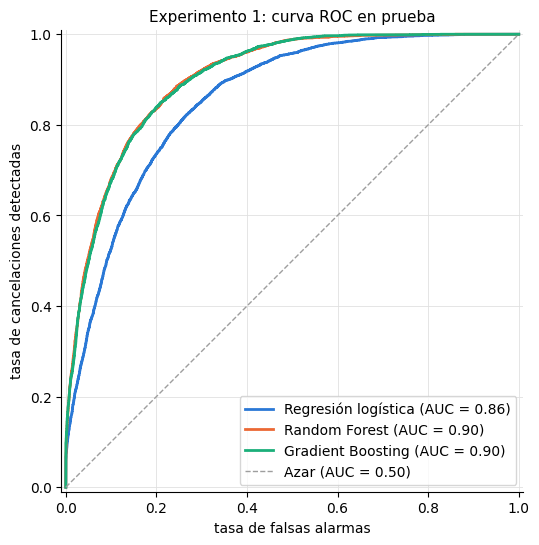

In [ ]:
graficar_curvas_roc(modelos_experimento_1, predictoras_prueba, objetivo_prueba, "Experimento 1: curva ROC en prueba")

**Resultado**: las curvas de Random Forest y Gradient Boosting casi se superponen (AUC 0,90) y quedan por encima de la regresión logística (0,86) en todos los umbrales.

## Paso 38. Experimento 1: importancia de las variables en Gradient Boosting

Gráfico de barras horizontales con una barra por variable: el largo de la barra indica cuánto aporta a la predicción, de mayor a menor. Las barras azules son las variables que aportan; las grises, las que aportan menos de 0,001 y se quitan en el Experimento 3. Se usa Gradient Boosting porque es el mejor modelo sin sobreajuste.

In [ ]:
importancia_experimento_1 = calcular_importancia(
    modelos_experimento_1["Gradient Boosting"],
    predictoras_entrenamiento[predictoras_experimento_1], objetivo_entrenamiento,
)
graficar_importancia(importancia_experimento_1, "Experimento 1: importancia de las variables en Gradient Boosting")

# Experimento 2: temporada con semana_llegada

Se repite el Experimento 1 cambiando solo la variable de temporada: se usa **semana_llegada** y se excluye **mes_llegada**. Cualquier diferencia en los resultados se debe a ese cambio.

## Paso 39. Experimento 2: entrenamiento de los modelos

In [ ]:
predictoras_experimento_2 = elegir_predictoras(list(predictoras_entrenamiento.columns), COLUMNAS_EXCLUIDAS_EXPERIMENTO_2)
print("Predictoras usadas:", len(predictoras_experimento_2))
modelos_experimento_2 = entrenar_modelos(
    crear_modelos(predictoras_experimento_2), predictoras_entrenamiento, objetivo_entrenamiento,
)

## Paso 40. Experimento 2: métricas de cada modelo en entrenamiento y prueba

In [ ]:
metricas_experimento_2 = evaluar_modelos(modelos_experimento_2, conjuntos, mostrar=True)

**Resultado**: el mismo comportamiento que en el Experimento 1: Random Forest con una diferencia de F1 de 0,077 y los otros dos con 0,020 o menos.

## Paso 41. Experimento 2: comparación de los modelos

In [ ]:
comparar_modelos(metricas_experimento_2)

,precision,recall,f1,auc
modelo,,,,
Random Forest,0.631,0.821,0.714,0.904
Gradient Boosting,0.603,0.848,0.705,0.903
Regresión logística,0.552,0.803,0.654,0.856


**Resultado**: prácticamente igual al Experimento 1: Random Forest 0,714, Gradient Boosting 0,705 (frente a 0,706) y regresión logística 0,654. Cambiar el mes por la semana no mejora los modelos.

## Paso 42. Experimento 2: matrices de confusión en prueba

In [ ]:
tabular_matrices_confusion(modelos_experimento_2, predictoras_prueba, objetivo_prueba)

**Resultado**: los valores cambian en menos de 20 reservas frente al Experimento 1, y las métricas, en milésimas.

## Paso 43. Experimento 2: curva ROC en prueba

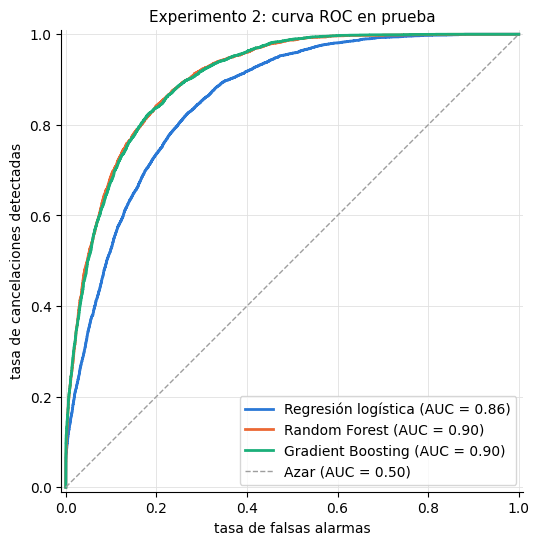

In [ ]:
graficar_curvas_roc(modelos_experimento_2, predictoras_prueba, objetivo_prueba, "Experimento 2: curva ROC en prueba")

**Resultado**: curvas iguales a las del Experimento 1 (AUC 0,90 en los árboles y 0,86 en la regresión logística).

# Experimento 3: sin las variables de menor aporte

Se parte del Experimento 1 (temporada con **mes_llegada**) y se quitan las variables cuya importancia en el Paso 38 es menor que 0,001 (barras grises), es decir, que al desordenarlas el F1 cae menos de una milésima. Si el F1 se mantiene, conviene el modelo más simple.

## Paso 44. Experimento 3: entrenamiento de los modelos

In [ ]:
variables_bajo_aporte = elegir_variables_bajo_aporte(importancia_experimento_1)
print("Variables de bajo aporte que se quitan:", variables_bajo_aporte)

columnas_excluidas_experimento_3 = COLUMNAS_EXCLUIDAS_EXPERIMENTO_1 + variables_bajo_aporte
predictoras_experimento_3 = elegir_predictoras(list(predictoras_entrenamiento.columns), columnas_excluidas_experimento_3)
print("Predictoras usadas:", len(predictoras_experimento_3))
modelos_experimento_3 = entrenar_modelos(
    crear_modelos(predictoras_experimento_3), predictoras_entrenamiento, objetivo_entrenamiento,
)

## Paso 45. Experimento 3: métricas de cada modelo en entrenamiento y prueba

In [ ]:
metricas_experimento_3 = evaluar_modelos(modelos_experimento_3, conjuntos, mostrar=True)

**Resultado**: las diferencias entre entrenamiento y prueba se mantienen: 0,077 en Random Forest y 0,016 o menos en los otros dos.

## Paso 46. Experimento 3: comparación de los modelos

In [ ]:
comparar_modelos(metricas_experimento_3)

,precision,recall,f1,auc
modelo,,,,
Random Forest,0.635,0.817,0.715,0.904
Gradient Boosting,0.603,0.854,0.707,0.903
Regresión logística,0.552,0.804,0.655,0.856


**Resultado**: con 4 predictoras menos (21 frente a 25), los tres modelos mantienen o mejoran levemente su F1: Random Forest 0,715, Gradient Boosting 0,707 y regresión logística 0,655.

## Paso 47. Experimento 3: matrices de confusión en prueba

In [ ]:
tabular_matrices_confusion(modelos_experimento_3, predictoras_prueba, objetivo_prueba)

**Resultado**: Gradient Boosting queda con 702 **cancelaciones_no_detectadas**, la menor cantidad de los tres experimentos, y un recall de 0,854.

## Paso 48. Experimento 3: curva ROC en prueba

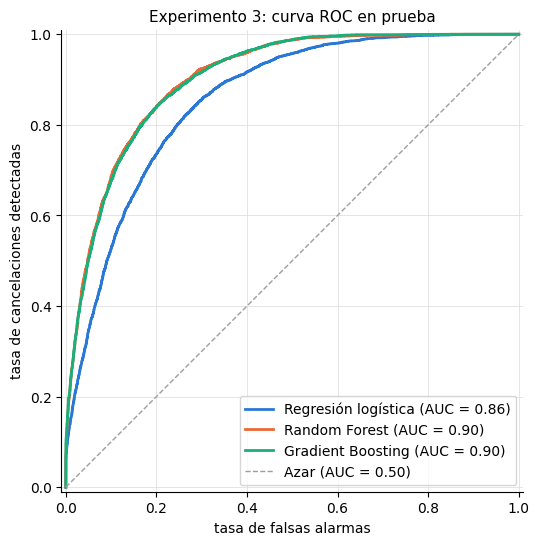

In [ ]:
graficar_curvas_roc(modelos_experimento_3, predictoras_prueba, objetivo_prueba, "Experimento 3: curva ROC en prueba")

**Resultado**: curvas iguales a las de los experimentos anteriores (AUC 0,90 y 0,86).

# Comparación de experimentos

## Paso 49. Comparación de todos los modelos de los tres experimentos

Se reúnen las métricas de prueba de los nueve modelos, con el número de predictoras que usa cada experimento y la diferencia de F1 entre entrenamiento y prueba de cada modelo.

In [ ]:
def comparar_experimentos(experimentos: dict[str, dict]) -> pd.DataFrame:
    """Reúne las métricas de prueba de todos los modelos de todos los experimentos, ordenadas por F1 y AUC."""
    filas = []
    for nombre_experimento in experimentos:
        experimento = experimentos[nombre_experimento]
        for nombre_modelo in experimento["metricas"]:
            tabla = experimento["metricas"][nombre_modelo]
            filas.append({
                "experimento": nombre_experimento,
                "modelo": nombre_modelo,
                "predictoras": len(experimento["predictoras"]),
                "precision": tabla.loc["precision", "prueba"],
                "recall": tabla.loc["recall", "prueba"],
                "f1": tabla.loc["f1", "prueba"],
                "auc": tabla.loc["auc", "prueba"],
                "diferencia_f1": tabla.loc["f1", "diferencia"],
            })
    comparacion = pd.DataFrame(filas)
    comparacion = comparacion.set_index(["experimento", "modelo"])
    return comparacion.sort_values(["f1", "auc"], ascending=False)


# Cada experimento con sus predictoras, sus modelos y sus métricas
experimentos = {
    "1. Con mes": {
        "predictoras": predictoras_experimento_1, "modelos": modelos_experimento_1, "metricas": metricas_experimento_1,
    },
    "2. Con semana": {
        "predictoras": predictoras_experimento_2, "modelos": modelos_experimento_2, "metricas": metricas_experimento_2,
    },
    "3. Sin bajo aporte": {
        "predictoras": predictoras_experimento_3, "modelos": modelos_experimento_3, "metricas": metricas_experimento_3,
    },
}
tabla_experimentos = comparar_experimentos(experimentos)
tabla_experimentos

**Conclusión**

- Las diferencias entre experimentos son de milésimas, dentro de lo que puede variar por azar; por eso se decide por simplicidad.
- **Variable de temporada**: mes y semana dan el mismo resultado; se elige **mes_llegada**, que es más simple (12 valores frente a 53).
- **Variables**: quitar las 4 de menor aporte no empeora ningún modelo; se elige el **Experimento 3**, con 21 predictoras.
- **Modelo recomendado**: **Gradient Boosting**. Random Forest tiene el F1 más alto (0,715), pero con indicios de sobreajuste en los tres experimentos (0,077); Gradient Boosting queda a solo 0,008 (0,707), detecta más cancelaciones (recall 0,854) y es estable entre entrenamiento y prueba.

# Exportación del mejor modelo

## Paso 50. Funciones de guardado y descarga del mejor modelo

Se guarda el pipeline elegido, que incluye la preparación (one-hot) y el modelo, junto con la lista de predictoras que espera, el umbral de decisión y la versión de scikit-learn con que se entrenó; la aplicación debe usar esa misma versión. En Colab el archivo además se descarga a la carpeta de descargas del computador, para copiarlo en la carpeta **modelos** del proyecto.

In [ ]:
def guardar_modelo(modelo: Pipeline, predictoras: list[str], ruta: str) -> None:
    """Guarda el pipeline entrenado con sus predictoras, su umbral de decisión y la versión de scikit-learn."""
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    paquete = {
        "modelo": modelo,
        "predictoras": predictoras,
        "umbral": UMBRAL_DECISION,
        "version_sklearn": sklearn.__version__,
    }
    joblib.dump(paquete, ruta)
    print("Modelo guardado en:", os.path.abspath(ruta))


def descargar_archivo(ruta: str) -> None:
    """En Colab descarga el archivo a la carpeta de descargas del computador; fuera de Colab ya queda en la carpeta de trabajo."""
    if archivos_colab is None:
        print("Fuera de Colab, el archivo ya está en la carpeta de trabajo:", ruta)
        return
    archivos_colab.download(ruta)

## Paso 51. Versiones del entorno

El modelo guardado solo carga con la misma versión de scikit-learn con que se entrenó. Por eso se muestran las versiones de este entorno: son las que debe tener el archivo **requirements.txt** de la aplicación.

In [ ]:
def obtener_versiones() -> pd.DataFrame:
    """Muestra la versión de Python y de cada librería que necesita la aplicación."""
    versiones = {"python": platform.python_version()}
    for nombre in LIBRERIAS_APLICACION:
        versiones[nombre] = LIBRERIAS_APLICACION[nombre].__version__
    return pd.DataFrame({"version": versiones})


obtener_versiones()

## Paso 52. Elección, guardado y descarga del mejor modelo

Se usa la tabla del Paso 49, que ya tiene el F1 de cada modelo en prueba y su diferencia entre entrenamiento y prueba. Primero se descartan los modelos con sobreajuste (diferencia mayor que 0,05); de los que quedan, el mejor es el de mayor F1 en prueba. Ese modelo se guarda en **modelos/modelo_cancelaciones.joblib** y se descarga.

In [ ]:
def elegir_mejor_modelo(tabla_experimentos: pd.DataFrame) -> tuple[str, str]:
    """Devuelve el experimento y el modelo con mayor F1 en prueba entre los que no tienen sobreajuste."""
    sin_sobreajuste = tabla_experimentos[tabla_experimentos["diferencia_f1"] <= UMBRAL_SOBREAJUSTE]
    return sin_sobreajuste["f1"].idxmax()   # fila con el F1 más alto: (experimento, modelo)


nombre_experimento, nombre_modelo = elegir_mejor_modelo(tabla_experimentos)
print(f"Mejor modelo: {nombre_modelo} del experimento {nombre_experimento}")

mejor_modelo = experimentos[nombre_experimento]["modelos"][nombre_modelo]
predictoras_mejor_modelo = experimentos[nombre_experimento]["predictoras"]
guardar_modelo(mejor_modelo, predictoras_mejor_modelo, RUTA_MODELO)
descargar_archivo(RUTA_MODELO)

# Flujo completo

## Paso 53. Función main: ejecución de todo el flujo

**main()** repite en orden todo el proceso con las funciones definidas en los pasos anteriores: extracción, transformación y carga de los datos, los tres experimentos, la elección del mejor modelo y su descarga (**modelo_cancelaciones.joblib**). Solo muestra mensajes de avance; los gráficos y las tablas del análisis están en los pasos anteriores.

In [ ]:
def ejecutar_experimento(
    columnas: list[str], columnas_excluidas: list[str], conjuntos: dict[str, tuple[pd.DataFrame, pd.Series]],
) -> dict:
    """Entrena los tres modelos con las predictoras de un experimento y calcula sus métricas sin mostrarlas."""
    predictoras = elegir_predictoras(columnas, columnas_excluidas)
    predictoras_entrenamiento, objetivo_entrenamiento = conjuntos["entrenamiento"]
    modelos = entrenar_modelos(crear_modelos(predictoras), predictoras_entrenamiento, objetivo_entrenamiento)
    return {
        "predictoras": predictoras,
        "modelos": modelos,
        "metricas": evaluar_modelos(modelos, conjuntos, mostrar=False),
    }


def main() -> None:
    """Ejecuta el flujo completo: ETL, experimentos, elección y descarga del mejor modelo."""
    # E: Extracción
    datos_originales = leer_datos(descargar_datos())

    # T: Transformación
    datos_renombrados = renombrar_columnas(datos_originales)
    datos_sin_duplicados = eliminar_duplicados(datos_renombrados)
    datos_sin_fugas = eliminar_columnas(datos_sin_duplicados, COLUMNAS_A_ELIMINAR)
    datos_validos = eliminar_filas_invalidas(datos_sin_fugas)
    datos_imputados = imputar_nulos(datos_validos)
    datos_corregidos = corregir_categorias(datos_imputados)
    datos_con_indicadores = crear_indicadores(datos_corregidos)
    datos_transformados = transformar_colas_largas(datos_con_indicadores)
    datos_limpios = codificar_ordinales(datos_transformados)
    validar_limpieza(datos_limpios)

    # L: Carga
    guardar_datos(datos_limpios, RUTA_DATOS_LIMPIOS)

    # Modelado: tres experimentos
    predictoras_entrenamiento, predictoras_prueba, objetivo_entrenamiento, objetivo_prueba = dividir_datos(datos_limpios)
    conjuntos = {
        "entrenamiento": (predictoras_entrenamiento, objetivo_entrenamiento),
        "prueba": (predictoras_prueba, objetivo_prueba),
    }
    columnas = list(predictoras_entrenamiento.columns)
    experimento_1 = ejecutar_experimento(columnas, COLUMNAS_EXCLUIDAS_EXPERIMENTO_1, conjuntos)
    experimento_2 = ejecutar_experimento(columnas, COLUMNAS_EXCLUIDAS_EXPERIMENTO_2, conjuntos)

    importancia_1 = calcular_importancia(
        experimento_1["modelos"]["Gradient Boosting"],
        predictoras_entrenamiento[experimento_1["predictoras"]], objetivo_entrenamiento,
    )
    variables_quitadas = elegir_variables_bajo_aporte(importancia_1)
    experimento_3 = ejecutar_experimento(columnas, COLUMNAS_EXCLUIDAS_EXPERIMENTO_1 + variables_quitadas, conjuntos)

    experimentos = {
        "1. Con mes": experimento_1,
        "2. Con semana": experimento_2,
        "3. Sin bajo aporte": experimento_3,
    }

    # Elección del mejor modelo
    tabla_experimentos = comparar_experimentos(experimentos)
    nombre_experimento, nombre_modelo = elegir_mejor_modelo(tabla_experimentos)
    print(f"Mejor modelo: {nombre_modelo} del experimento {nombre_experimento}")

    # Exportación del mejor modelo
    mejor_modelo = experimentos[nombre_experimento]["modelos"][nombre_modelo]
    predictoras_mejor_modelo = experimentos[nombre_experimento]["predictoras"]
    guardar_modelo(mejor_modelo, predictoras_mejor_modelo, RUTA_MODELO)
    descargar_archivo(RUTA_MODELO)


if __name__ == "__main__":
    main()